In [10]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt
from skfuzzy import control as ctrl

In [11]:
Speed= ctrl.Antecedent(np.arange(0, 121, 0.1), 'Speed')
Road_condition= ctrl.Antecedent(np.arange(0, 11, 0.1), 'Road_condition')
Driver_alertness = ctrl.Antecedent(np.arange(0, 11, 0.1), 'Driver_alertness')
Risk_level = ctrl.Consequent(np.arange(0, 11, 0.1), 'Risk_level')

In [12]:
Speed['slow'] = fuzz.trimf(Speed.universe, [0, 25, 50])
Speed['medium'] = fuzz.trimf(Speed.universe, [30, 55, 80])
Speed['fast'] = fuzz.trimf(Speed.universe, [70, 100, 120])
Road_condition['poor'] = fuzz.trimf(Road_condition.universe, [0, 2, 6])
Road_condition['normal'] = fuzz.trimf(Road_condition.universe, [4, 5, 8 ])
Road_condition['good'] = fuzz.trimf(Road_condition.universe, [7, 8, 10])
Driver_alertness['low'] = fuzz.trimf(Driver_alertness.universe, [0, 3, 5.5])
Driver_alertness['medium'] = fuzz.trimf(Driver_alertness.universe, [4 , 6 ,8 ])
Driver_alertness['high'] = fuzz.trimf(Driver_alertness.universe, [6.5, 8, 10])
Risk_level['low_risk'] = fuzz.trimf(Risk_level.universe, [0, 2, 4 ])
Risk_level['medium_risk'] = fuzz.trimf(Risk_level.universe,[3.5, 5.5 ,7])
Risk_level['high_risk'] = fuzz.trimf(Risk_level.universe, [6.5, 8 , 10])

In [13]:
rule1  = ctrl.Rule(Speed['fast'] & Road_condition['poor'] & Driver_alertness['low'],    Risk_level['high_risk'])
rule2  = ctrl.Rule(Speed['fast'] & Road_condition['poor'] & Driver_alertness['medium'], Risk_level['high_risk'])
rule3  = ctrl.Rule(Speed['fast'] & Road_condition['poor'] & Driver_alertness['high'],   Risk_level['high_risk'])
rule4  = ctrl.Rule(Speed['fast'] & Road_condition['normal'] & Driver_alertness['low'],  Risk_level['high_risk'])
rule5  = ctrl.Rule(Speed['fast'] & Road_condition['normal'] & Driver_alertness['medium'], Risk_level['high_risk'])
rule6  = ctrl.Rule(Speed['fast'] & Road_condition['normal'] & Driver_alertness['high'], Risk_level['medium_risk'])
rule7  = ctrl.Rule(Speed['fast'] & Road_condition['good'] & Driver_alertness['low'],    Risk_level['high_risk'])
rule8  = ctrl.Rule(Speed['fast'] & Road_condition['good'] & Driver_alertness['medium'], Risk_level['medium_risk'])
rule9  = ctrl.Rule(Speed['fast'] & Road_condition['good'] & Driver_alertness['high'],   Risk_level['medium_risk'])
rule10 = ctrl.Rule(Speed['medium'] & Road_condition['poor'] & Driver_alertness['low'],    Risk_level['high_risk'])
rule11 = ctrl.Rule(Speed['medium'] & Road_condition['poor'] & Driver_alertness['medium'], Risk_level['medium_risk'])
rule12 = ctrl.Rule(Speed['medium'] & Road_condition['poor'] & Driver_alertness['high'],   Risk_level['medium_risk'])
rule13 = ctrl.Rule(Speed['medium'] & Road_condition['normal'] & Driver_alertness['low'],  Risk_level['medium_risk'])
rule14 = ctrl.Rule(Speed['medium'] & Road_condition['normal'] & Driver_alertness['medium'], Risk_level['medium_risk'])
rule15 = ctrl.Rule(Speed['medium'] & Road_condition['normal'] & Driver_alertness['high'], Risk_level['low_risk'])
rule16 = ctrl.Rule(Speed['medium'] & Road_condition['good'] & Driver_alertness['low'],    Risk_level['medium_risk'])
rule17 = ctrl.Rule(Speed['medium'] & Road_condition['good'] & Driver_alertness['medium'], Risk_level['low_risk'])
rule18 = ctrl.Rule(Speed['medium'] & Road_condition['good'] & Driver_alertness['high'],   Risk_level['low_risk'])
rule19 = ctrl.Rule(Speed['slow'] & Road_condition['poor'] & Driver_alertness['low'],    Risk_level['medium_risk'])
rule20 = ctrl.Rule(Speed['slow'] & Road_condition['poor'] & Driver_alertness['medium'], Risk_level['medium_risk'])
rule21 = ctrl.Rule(Speed['slow'] & Road_condition['poor'] & Driver_alertness['high'],   Risk_level['low_risk'])
rule22 = ctrl.Rule(Speed['slow'] & Road_condition['normal'] & Driver_alertness['low'],  Risk_level['medium_risk'])
rule23 = ctrl.Rule(Speed['slow'] & Road_condition['normal'] & Driver_alertness['medium'], Risk_level['low_risk'])
rule24 = ctrl.Rule(Speed['slow'] & Road_condition['normal'] & Driver_alertness['high'], Risk_level['low_risk'])
rule25 = ctrl.Rule(Speed['slow'] & Road_condition['good'] & Driver_alertness['low'],    Risk_level['low_risk'])
rule26 = ctrl.Rule(Speed['slow'] & Road_condition['good'] & Driver_alertness['medium'], Risk_level['low_risk'])
rule27 = ctrl.Rule(Speed['slow'] & Road_condition['good'] & Driver_alertness['high'],   Risk_level['low_risk'])

In [14]:
Risk_level_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5,rule6, rule7, rule8, rule9,rule10, rule11, rule12, rule13, rule14,rule15, rule16, rule17, rule18,rule19, rule20, rule21, rule22,rule23, rule24, rule25, rule26, rule27])
Risk_level_simulation = ctrl.ControlSystemSimulation(Risk_level_ctrl)

In [15]:
Risk_level_simulation.input['Speed'] = 80  
Risk_level_simulation.input['Road_condition'] = 6  
Risk_level_simulation.input['Driver_alertness'] = 3   

In [16]:
Risk_level_simulation.compute()

In [17]:
print(f"Risk level is : {Risk_level_simulation.output['Risk_level']:.2f}")

Risk level is : 8.21


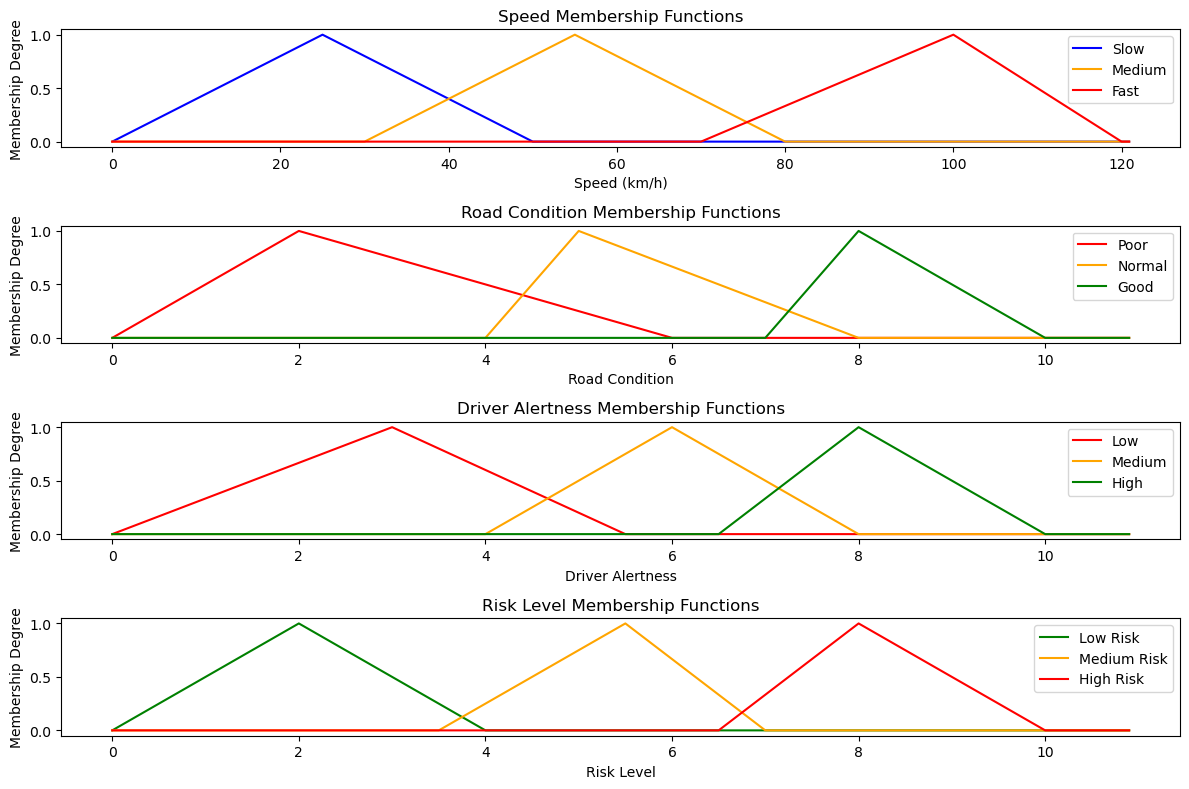

In [18]:
plt.figure(figsize=(12, 8))

# Speed
plt.subplot(4, 1, 1)
plt.plot(Speed.universe, Speed['slow'].mf, 'b', label='Slow')
plt.plot(Speed.universe, Speed['medium'].mf, 'orange', label='Medium')
plt.plot(Speed.universe, Speed['fast'].mf, 'r', label='Fast')
plt.title('Speed Membership Functions')
plt.xlabel('Speed (km/h)')
plt.ylabel('Membership Degree')
plt.legend()

# Road Condition
plt.subplot(4, 1, 2)
plt.plot(Road_condition.universe, Road_condition['poor'].mf, 'r', label='Poor')
plt.plot(Road_condition.universe, Road_condition['normal'].mf, 'orange', label='Normal')
plt.plot(Road_condition.universe, Road_condition['good'].mf, 'g', label='Good')
plt.title('Road Condition Membership Functions')
plt.xlabel('Road Condition')
plt.ylabel('Membership Degree')
plt.legend()

# Driver Alertness
plt.subplot(4, 1, 3)
plt.plot(Driver_alertness.universe, Driver_alertness['low'].mf, 'r', label='Low')
plt.plot(Driver_alertness.universe, Driver_alertness['medium'].mf, 'orange', label='Medium')
plt.plot(Driver_alertness.universe, Driver_alertness['high'].mf, 'g', label='High')
plt.title('Driver Alertness Membership Functions')
plt.xlabel('Driver Alertness')
plt.ylabel('Membership Degree')
plt.legend()

# Risk Level
plt.subplot(4, 1, 4)
plt.plot(Risk_level.universe, Risk_level['low_risk'].mf, 'g', label='Low Risk')
plt.plot(Risk_level.universe, Risk_level['medium_risk'].mf, 'orange', label='Medium Risk')
plt.plot(Risk_level.universe, Risk_level['high_risk'].mf, 'r', label='High Risk')
plt.title('Risk Level Membership Functions')
plt.xlabel('Risk Level')
plt.ylabel('Membership Degree')
plt.legend()

plt.tight_layout()
plt.show()